In [1]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import ZGate
from qiskit_aer import AerSimulator

qreg_q = QuantumRegister(2, 'q')
creg_c = ClassicalRegister(2, 'c')
circuit = QuantumCircuit(qreg_q, creg_c)

#superposition
circuit.h(qreg_q[0])
circuit.h(qreg_q[1])

circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])

#oracle target state |11>
circuit.append(ZGate().control(1), [qreg_q[1], qreg_q[0]])
circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])

#diffuser operator
circuit.h(qreg_q[0])
circuit.h(qreg_q[1])
circuit.x(qreg_q[0])
circuit.x(qreg_q[1])
circuit.append(ZGate().control(1), [qreg_q[1], qreg_q[0]])
circuit.x(qreg_q[0])
circuit.x(qreg_q[1])
circuit.h(qreg_q[1])
circuit.h(qreg_q[0])

circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])

#measurement
circuit.measure(qreg_q[0], creg_c[0])
circuit.measure(qreg_q[1], creg_c[1])

#execute the circuit on AerSimulator
simulator = AerSimulator()
job = simulator.run(circuit, shots=1024)
result = job.result()
counts = result.get_counts(circuit)

print("Execution counts:", counts)

Execution counts: {'11': 1024}


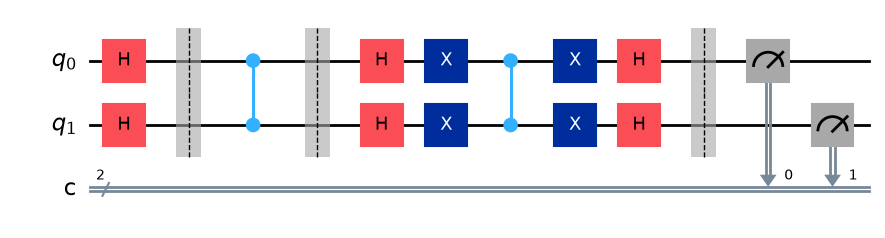

In [2]:
circuit.draw('mpl')

In [3]:
print(circuit.draw('text'))

     ┌───┐ ░     ░ ┌───┐┌───┐   ┌───┐┌───┐ ░ ┌─┐   
q_0: ┤ H ├─░──■──░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░─┤M├───
     ├───┤ ░  │  ░ ├───┤├───┤ │ ├───┤├───┤ ░ └╥┘┌─┐
q_1: ┤ H ├─░──■──░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░──╫─┤M├
     └───┘ ░     ░ └───┘└───┘   └───┘└───┘ ░  ║ └╥┘
c: 2/═════════════════════════════════════════╩══╩═
                                              0  1 


CNOT Count: 2
Circuit Depth: 16


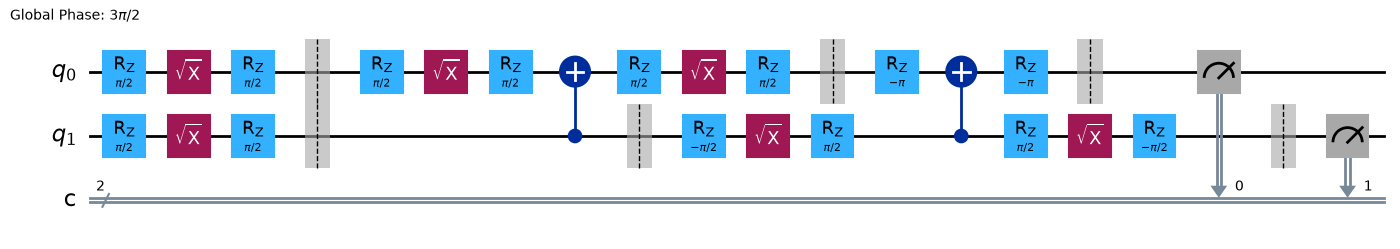

In [4]:
from qiskit import transpile

# Define hardware basis gates
basis_gates = ['cx', 'id', 'rz', 'sx', 'x']

# Transpile circuit to basis gates
transpiled_qc = transpile(circuit, basis_gates=basis_gates, optimization_level=1)

# Display CNOT overhead and circuit depth
cnot_count = transpiled_qc.count_ops().get('cx', 0)
depth = transpiled_qc.depth()

print(f"CNOT Count: {cnot_count}")
print(f"Circuit Depth: {depth}")

transpiled_qc.draw('mpl')